### Predicting Cholorphyll-A (Green Color) Levels in Laguna Lake

In this experiment, we will be predicting the Chlorophyll-A levels in Laguna Lake. This lake provides drinking water to the population in Metro Manila when the water is treated, and high levels of Chloropyll-A (the water is too green) can lead to water shortages.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, Matern, RationalQuadratic, DotProduct
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import mean_squared_error, r2_score


### Exploratory Data Analysis

In [2]:
df = pd.read_csv('chlor.csv')
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Chl_a   255 non-null    float64
 1   Phy     255 non-null    float64
 2   NO2     109 non-null    float64
 3   NO3     109 non-null    float64
 4   NH4     109 non-null    float64
 5   PO4     109 non-null    float64
 6   Site    255 non-null    object 
 7   Bay     255 non-null    object 
 8   Depth   255 non-null    float64
dtypes: float64(7), object(2)
memory usage: 18.1+ KB
None


In [3]:
df.drop(columns=['Phy', 'Site', 'Bay', 'Depth'], inplace=True)

In [4]:
df.isnull().sum()

Chl_a      0
NO2      146
NO3      146
NH4      146
PO4      146
dtype: int64

In [5]:
clean_df = df.dropna()

In [6]:
print("Null Values:\n", clean_df.isnull().sum())
print("\nShape", clean_df.shape)
print("\nColumns:", clean_df.columns.tolist())

Null Values:
 Chl_a    0
NO2      0
NO3      0
NH4      0
PO4      0
dtype: int64

Shape (109, 5)

Columns: ['Chl_a', 'NO2', 'NO3', 'NH4', 'PO4']


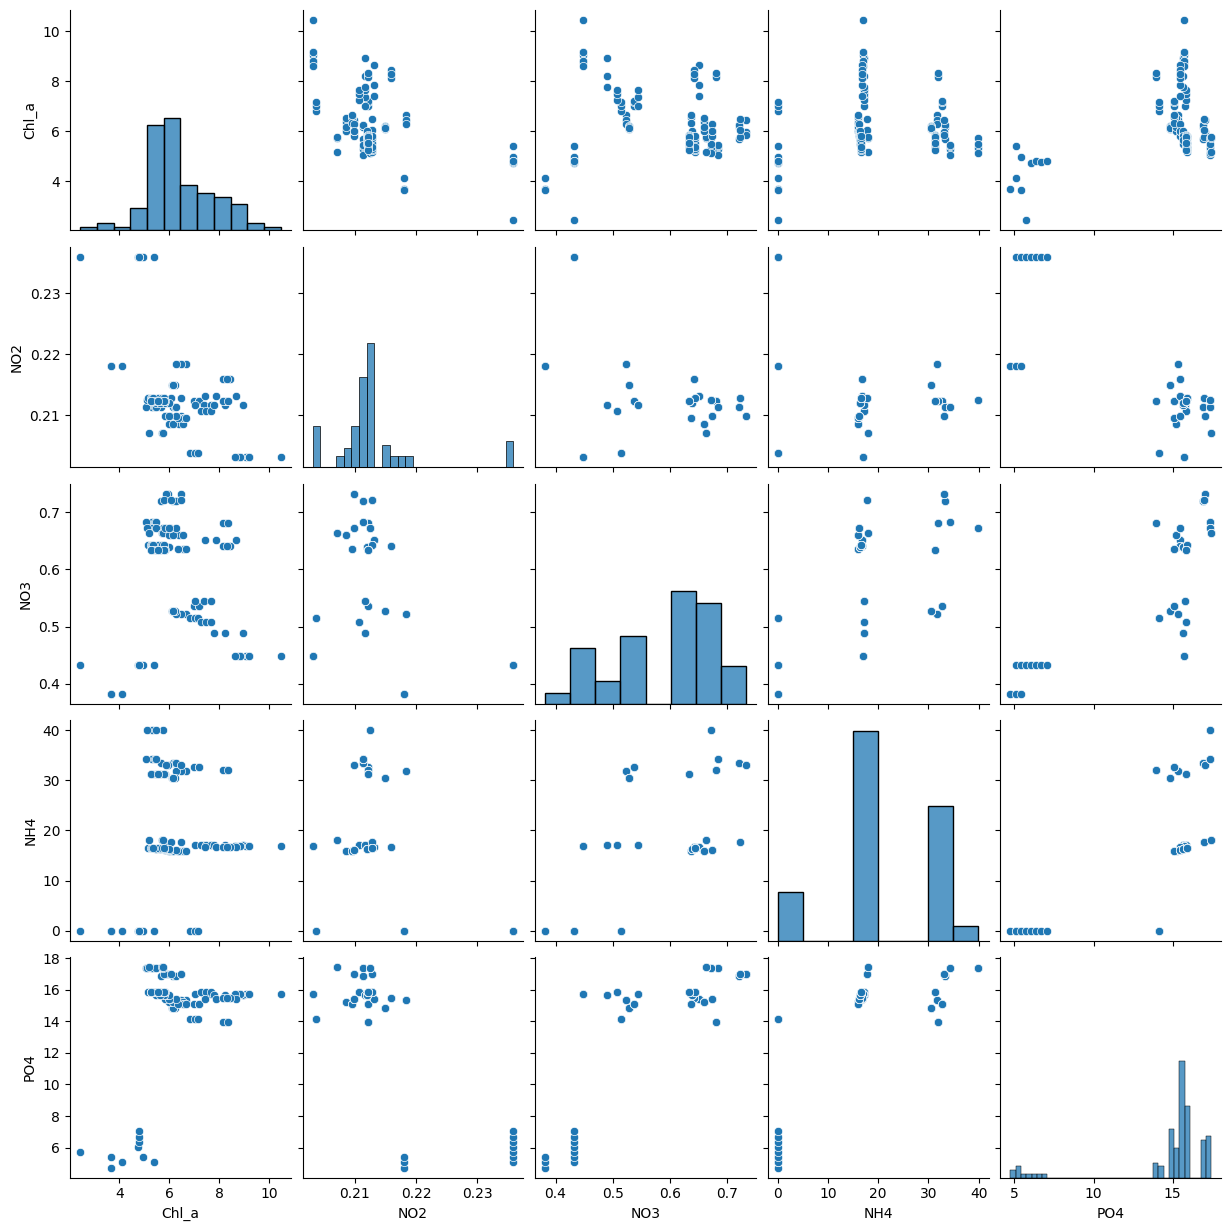

In [7]:
sns.pairplot(clean_df)
plt.show()

In [8]:
features = clean_df.drop(columns=['Chl_a'])
labels = clean_df['Chl_a']

In [9]:
print("Shape of features:", features.shape)
print("Shape of labels:", labels.shape)
print("Feature columns:", features.columns.tolist())

Shape of features: (109, 4)
Shape of labels: (109,)
Feature columns: ['NO2', 'NO3', 'NH4', 'PO4']


### Train/Test Split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.3, random_state=42)

print("Shape of X_train (training data):", X_train.shape)
print("Shape of y_train (training labels):", y_train.shape)
print("Shape of X_test (test data):", X_test.shape)
print("Shape of y_test (test labels):", y_test.shape)

Shape of X_train (training data): (76, 4)
Shape of y_train (training labels): (76,)
Shape of X_test (test data): (33, 4)
Shape of y_test (test labels): (33,)


## Gaussian Process Regressor

In [15]:
# Create a pipeline that includes standard scaling and the Gaussian Process Regressor
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('gpr', GaussianProcessRegressor(normalize_y=True, n_restarts_optimizer=10, random_state=42))
])

# Define a list of kernels to search over for the Gaussian Process Regressor
# We will include RBF, Matern (with different nu values), and RationalQuadratic kernels
kernels = [
    RBF(length_scale=1.0, length_scale_bounds=(1e-10, 1e6)),
    Matern(length_scale=1.0, nu=1.5, length_scale_bounds=(1e-10, 1e6)),
    Matern(length_scale=1.0, nu=2.5, length_scale_bounds=(1e-10, 1e6)),
    RationalQuadratic(length_scale=1.0, alpha=1.0,
                      length_scale_bounds=(1e-10, 1e6),
                      alpha_bounds=(1e-10, 1e6)),
]

# Define the hyperparameters to search over for the Gaussian Process Regressor
param_grid = {
    'gpr__kernel': kernels,
    'gpr__alpha': [1e-5, 1e-2, 1e-1, 1.0, 10.0]
}

# Perform grid search with 5-fold cross-validation to find the best hyperparameters
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='neg_root_mean_squared_error')
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV RMSE:", -grid_search.best_score_)

# Evaluate the best model on the test set and calculate RMSE
best_pipeline = grid_search.best_estimator_
# Predict on the test set
y_pred = best_pipeline.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("Test RMSE:", test_rmse)

# Calculate and print training and test accuracy
train_accuracy = best_pipeline.score(X_train, y_train)
test_accuracy = best_pipeline.score(X_test, y_test)
print("Training Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)

# Get the r2 score for the test set
r2 = r2_score(y_test, y_pred)
print("R2 Score on Test Set:", r2)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter alpha is close to the specified upper bound 1000000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter alpha is close to the specified upper bound 1000000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter alpha is close to the specified upper bound 1000000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn

Best Parameters: {'gpr__alpha': 1e-05, 'gpr__kernel': RationalQuadratic(alpha=1, length_scale=1)}
Best CV RMSE: 0.5174365542648254
Test RMSE: 0.539006583717572
Training Accuracy: 0.9568963885403614
Test Accuracy: 0.8606697073794908
R2 Score on Test Set: 0.8606697073794908


# Kernel Ridge Regression

In [ ]:
pipeline_krr = Pipeline([
    ('scaler', StandardScaler()),
    ('krr', KernelRidge())
])

param_grid_krr = {
    'krr__kernel': ['rbf', 'sigmoid', 'polynomial', 'linear'],  # kernel types
    'krr__alpha': [1e-3, 1e-2, 0.1, 1.0, 10.0],   # regularization
    'krr__gamma': [1e-3, 1e-2, 0.1, 1.0, 10.0],    # kernel parameter (1 / (2 * length_scale^2))
}

grid_search_krr = GridSearchCV(
    pipeline_krr,
    param_grid_krr,
    cv=5,
    scoring='neg_root_mean_squared_error',
    verbose=1
)

grid_search_krr.fit(X_train, y_train)

print("Best Parameters:", grid_search_krr.best_params_)
print("Best CV RMSE:", -grid_search_krr.best_score_)

# Evaluate on test set
best_krr = grid_search_krr.best_estimator_
y_pred_krr = best_krr.predict(X_test)

test_rmse_krr = np.sqrt(mean_squared_error(y_test, y_pred_krr))
print("Test RMSE:", test_rmse_krr)

train_accuracy_krr = best_krr.score(X_train, y_train)
test_accuracy_krr = best_krr.score(X_test, y_test)
print("Training Accuracy:", train_accuracy_krr)
print("Test Accuracy:", test_accuracy_krr)


Fitting 5 folds for each of 100 candidates, totalling 500 fits


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model

Best Parameters: {'krr__alpha': 0.01, 'krr__gamma': 0.1, 'krr__kernel': 'rbf'}
Best CV RMSE: 0.6155222742365225
Test RMSE: 0.8468537505348998
Training Accuracy: 0.8841619235957123
Test Accuracy: 0.6560666895730833


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_ridge.py:255: UserWarning: Singular matrix in solving dual problem. Using least-squares solution instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model

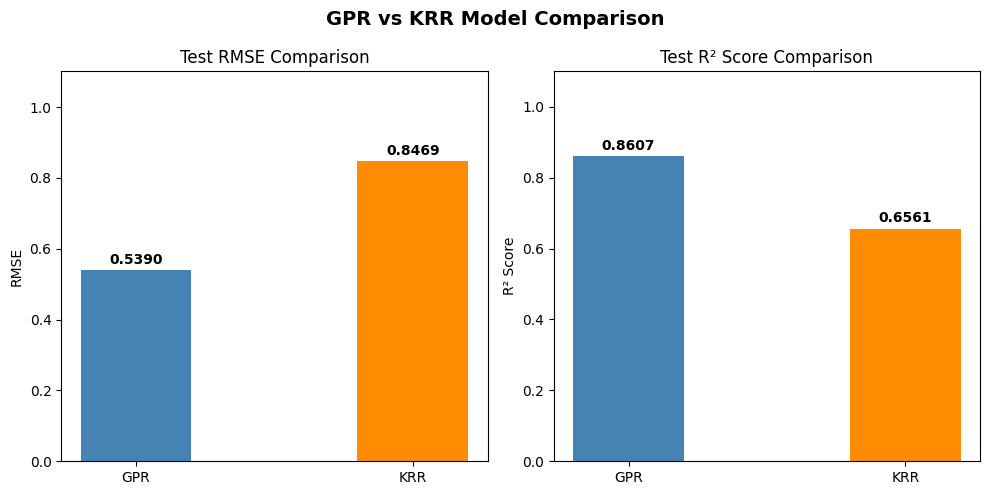

GPR  — Test RMSE: 0.5390 | R²: 0.8607
KRR  — Test RMSE: 0.8469 | R²: 0.6561


In [13]:
# Compare GPR vs KRR
gpr_test_rmse = test_rmse
krr_test_rmse = test_rmse_krr
gpr_test_r2 = r2_score(y_test, y_pred)
krr_test_r2 = r2_score(y_test, y_pred_krr)

models = ["GPR", "KRR"]
rmse_values = [gpr_test_rmse, krr_test_rmse]
r2_values = [gpr_test_r2, krr_test_r2]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# RMSE comparison
bars1 = axes[0].bar(models, rmse_values, color=["steelblue", "darkorange"], width=0.4)
axes[0].set_title("Test RMSE Comparison")
axes[0].set_ylabel("RMSE")
axes[0].set_ylim(0, max(rmse_values) * 1.3)
for bar, val in zip(bars1, rmse_values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                 f"{val:.4f}", ha="center", va="bottom", fontweight="bold")

# R2 comparison
bars2 = axes[1].bar(models, r2_values, color=["steelblue", "darkorange"], width=0.4)
axes[1].set_title("Test R² Score Comparison")
axes[1].set_ylabel("R² Score")
axes[1].set_ylim(0, 1.1)
for bar, val in zip(bars2, r2_values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                 f"{val:.4f}", ha="center", va="bottom", fontweight="bold")

plt.suptitle("GPR vs KRR Model Comparison", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"GPR  — Test RMSE: {gpr_test_rmse:.4f} | R²: {gpr_test_r2:.4f}")
print(f"KRR  — Test RMSE: {krr_test_rmse:.4f} | R²: {krr_test_r2:.4f}")

## Results and Discussion

### Summary of Models

| Model | Test RMSE | Test R² |
|-------|-----------|---------|
| Gaussian Process Regressor (GPR) | ~0.539 | ~0.861 |
| Kernel Ridge Regression (KRR) | ~0.847 | ~0.656 |

### Key Findings

**Gaussian Process Regressor (GPR)** outperformed KRR on this dataset across both metrics:
- **Lower RMSE**: GPR achieved a test RMSE of ~0.539 compared to KRR's ~0.847, meaning GPR's predictions deviate less from the true Chl-a values on average.
- **Higher R²**: GPR explained ~86% of the variance in the test set versus ~66% for KRR, indicating a substantially better fit.

The best GPR configuration used a **RationalQuadratic kernel** with alpha=1e-5, which is well-suited to capturing multi-scale patterns in nutrient-to-chlorophyll relationships. GPR also benefits from being a probabilistic model that naturally quantifies prediction uncertainty.

KRR with an **RBF kernel** (gamma=0.1, alpha=0.01) performed reasonably but showed more overfitting (train R² ~0.884 vs test R² ~0.656). This gap suggests that KRR generalizes less effectively to unseen data for this particular dataset.

### Practical Implications

For predicting Chlorophyll-A levels in Laguna Lake — a public health concern for Metro Manila's water supply — GPR is the more reliable model. Its lower prediction error could help water managers make more accurate decisions about treatment needs when nutrient levels (NO₂, NO₃, NH₄, PO₄) are measured.